#DS607 Group Project (2026)

**Research Question: Does the VIX (as a proxy for investor fear/sentiment) predict subsequent S&P 500 returns, and does this relationship differ between high-VIX and low-VIX periods?**


Step 1 : Data Preparation

Step 2 : Descriptive exploration

Step 3 : Baseline regression (VIX only)

Step 4 : Extended regression (VIX + dividend yield)

Step 5 : Block-bootstrap inference

Step 6 : High- vs. low-VIX regime comparison

Step 7 : Nonparametric test: permutation test on β


**Step 1**

Data preparation
- Resample daily VIX to month-end value, aligned to CRSP's month-end convention
- Construct dividend yield control: `DIVₜ = MthTotRetₜ − MthPrcRetₜ`
- Handle the 4 non-month-end VIX gaps (confirm no impact; document the fix used, e.g. forward-fill or drop)
- Lag VIX and DIV by one month to align with `Rₜ₊₁` (next-month return)
- Merge into a single analysis-ready monthly dataset (`data/processed/merged_monthly.csv`)
- Construct High/Low-VIX regime indicator (median split or VIX = 20 threshold)
- Save intermediate/working files (e.g. resampled VIX before merge) to `data/interim/`


In [ ]:
# ==============================================================================
# DS607 Project — Data Preparation Pipeline
# ==============================================================================

# --- Part 1: Mount Google Drive ---
from google.colab import drive

drive.mount("/content/drive")

# All project files live under this folder in your Drive. Change PROJECT_ROOT
# if you'd rather use a different path/folder name.
PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"


# --- Part 2: Setup folders ---
import os

for folder in ["data/raw", "data/interim", "data/processed"]:
    os.makedirs(f"{PROJECT_ROOT}/{folder}", exist_ok=True)

print("Folders ready:", os.listdir(f"{PROJECT_ROOT}/data"))


# --- Part 3: Place raw files in Drive (one-time step) ---
# Manually upload SP_500_Index-2001-2025.csv and VIX-2001-2025.csv into:
#   MyDrive/DS607 Group Project/data/raw/
# via the Google Drive web UI or app — no code needed for this step. Once
# they're there, they'll persist across sessions and every future notebook
# run can just read from this path directly.

# Sanity check that the files are visible from Colab:
raw_dir = f"{PROJECT_ROOT}/data/raw"
print("Files in data/raw:", os.listdir(raw_dir))


# --- Part 4: Load raw data ---
import pandas as pd
import numpy as np

sp500 = pd.read_csv(f"{PROJECT_ROOT}/data/raw/SP_500_Index-2001-2025.csv")
vix = pd.read_csv(f"{PROJECT_ROOT}/data/raw/VIX-2001-2025.csv")

print("S&P 500 raw shape:", sp500.shape)
print("VIX raw shape:", vix.shape)




Mounted at /content/drive
Folders ready: ['raw', 'interim', 'processed']
Files in data/raw: ['VIX-2001-2025.csv', 'SP_500_Index-2001-2025.csv']
S&P 500 raw shape: (300, 26)
VIX raw shape: (6321, 2)


In [ ]:
# --- Part 5: Clean S&P 500 monthly returns + construct dividend yield ---
sp500["MthCalDt"] = pd.to_datetime(sp500["MthCalDt"])
sp500 = sp500.sort_values("MthCalDt").reset_index(drop=True)
sp500["year_month"] = sp500["MthCalDt"].dt.to_period("M")

sp500_clean = sp500[["year_month", "MthCalDt", "MthPrcRet", "MthTotRet"]].copy()
sp500_clean = sp500_clean.rename(columns={
    "MthCalDt": "month_end_date",
    "MthPrcRet": "price_return",
    "MthTotRet": "total_return",
})

# Dividend yield control: DIV_t = TotalReturn_t - PriceReturn_t
sp500_clean["div_yield"] = sp500_clean["total_return"] - sp500_clean["price_return"]

# Sanity checks
assert sp500_clean["year_month"].duplicated().sum() == 0, "Duplicate months found!"
assert sp500_clean.isna().sum().sum() == 0, "Unexpected missing values in S&P 500 data!"

print("S&P 500 clean shape:", sp500_clean.shape)
sp500_clean.head()


# --- Part 6: Clean daily VIX, handle gaps, resample to month-end ---
vix["date"] = pd.to_datetime(vix["date"])
vix = vix.sort_values("date").reset_index(drop=True)

n_missing = vix["vix"].isna().sum()
print(f"Missing daily VIX values before fill: {n_missing}")

# Forward-fill the 4 known non-month-end gaps (documented in proposal Section 4.3)
vix["vix"] = vix["vix"].ffill()
print(f"Missing daily VIX values after ffill: {vix['vix'].isna().sum()}")

# Resample: take the last available trading-day value in each month
vix["year_month"] = vix["date"].dt.to_period("M")
vix_month_end = (
    vix.sort_values("date")
    .groupby("year_month")
    .last()
    .reset_index()
    .rename(columns={"date": "vix_date", "vix": "vix_level"})
    [["year_month", "vix_date", "vix_level"]]
)

print("VIX month-end shape:", vix_month_end.shape)
vix_month_end.head()


# --- Part 7: Save interim VIX (working data, before merge) ---
vix_month_end.to_csv(f"{PROJECT_ROOT}/data/interim/vix_month_end.csv", index=False)
print(f"Saved {PROJECT_ROOT}/data/interim/vix_month_end.csv")


# --- Part 8: Merge datasets ---
merged = pd.merge(sp500_clean, vix_month_end, on="year_month", how="inner")
merged = merged.sort_values("year_month").reset_index(drop=True)

print("Merged shape (pre-lag):", merged.shape)
merged.head()


# --- Part 9: Lag structure — VIX_t, DIV_t predict R_{t+1} ---
# next_month_return is price_return shifted back by one month, so each row's
# VIX_t and DIV_t line up with next month's return, avoiding contemporaneous
# feedback between VIX and returns.
merged["next_month_return"] = merged["price_return"].shift(-1)

# Drop the last row (no next-month return available to predict)
merged_final = merged.dropna(subset=["next_month_return"]).reset_index(drop=True)

print("Final shape after lagging:", merged_final.shape)
merged_final.tail()


# --- Part 10: Construct High/Low-VIX regime indicators ---
median_vix = merged_final["vix_level"].median()
merged_final["regime_median"] = np.where(
    merged_final["vix_level"] >= median_vix, "high", "low"
)
merged_final["regime_threshold20"] = np.where(
    merged_final["vix_level"] >= 20, "high", "low"
)

print("Median VIX split (threshold = {:.2f}):".format(median_vix))
print(merged_final["regime_median"].value_counts())
print("\nVIX = 20 threshold split:")
print(merged_final["regime_threshold20"].value_counts())


# --- Part 11: Save final analysis-ready dataset ---
merged_final.to_csv(f"{PROJECT_ROOT}/data/processed/merged_monthly.csv", index=False)
print(f"Saved {PROJECT_ROOT}/data/processed/merged_monthly.csv — shape:", merged_final.shape)
merged_final.head()


# --- Part 12: Quick sanity summary  ---
print("=" * 60)
print("DATA PREPARATION SUMMARY")
print("=" * 60)
print(f"Date range: {merged_final['year_month'].min()} to {merged_final['year_month'].max()}")
print(f"Observations (after lag): {len(merged_final)}")
print(f"Missing values in final dataset: {merged_final.isna().sum().sum()}")
print(f"VIX range: {merged_final['vix_level'].min():.2f} to {merged_final['vix_level'].max():.2f}")
print(f"Median VIX (regime split point): {median_vix:.2f}")
print(f"Dividend yield range: {merged_final['div_yield'].min():.5f} to {merged_final['div_yield'].max():.5f}")


# --- Part 13: Confirm everything persisted to Drive ---
# Since PROJECT_ROOT points into Google Drive, these files now persist across
# Colab sessions automatically — no manual download/upload needed next time.
# Just re-run Part 1 (mount) and Part 4 onward (or reload merged_monthly.csv
# directly) in future sessions.
print("Interim files:", os.listdir(f"{PROJECT_ROOT}/data/interim"))
print("Processed files:", os.listdir(f"{PROJECT_ROOT}/data/processed"))
print(f"\nAll data now stored under: {PROJECT_ROOT}")


S&P 500 clean shape: (300, 5)
Missing daily VIX values before fill: 4
Missing daily VIX values after ffill: 0
VIX month-end shape: (300, 3)
Saved /content/drive/MyDrive/DS607 Group Project/data/interim/vix_month_end.csv
Merged shape (pre-lag): (300, 7)
Final shape after lagging: (299, 8)
Median VIX split (threshold = 17.44):
regime_median
high    150
low     149
Name: count, dtype: int64

VIX = 20 threshold split:
regime_threshold20
low     192
high    107
Name: count, dtype: int64
Saved /content/drive/MyDrive/DS607 Group Project/data/processed/merged_monthly.csv — shape: (299, 10)
DATA PREPARATION SUMMARY
Date range: 2001-01 to 2025-11
Observations (after lag): 299
Missing values in final dataset: 0
VIX range: 9.51 to 59.89
Median VIX (regime split point): 17.44
Dividend yield range: 0.00068 to 0.00499
Interim files: ['vix_month_end.csv']
Processed files: ['merged_monthly.csv']

All data now stored under: /content/drive/MyDrive/DS607 Group Project


**Step 2**

Descriptive Analysis

- Time series plot: VIX and S&P 500 returns over 2001–2025
- Return histogram / Q-Q plot (check non-normality)
- VIX-vs-next-month-return scatter plot
- Summary statistics table (mean, SD, min/max) for returns, VIX, dividend yield
- Correlation / VIF between VIXₜ and DIVₜ (multicollinearity check)

In [ ]:
# ==============================================================================
# DS607 Project — Descriptive Analysis
# ==============================================================================

# --- Part 1: Setup ---
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
FIG_DIR = f"{PROJECT_ROOT}/outputs/figures"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


# --- Part 2: Load the analysis-ready dataset ---
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv")
df["month_end_date"] = pd.to_datetime(df["month_end_date"])

print("Shape:", df.shape)
df.head()



Shape: (299, 10)


,year_month,month_end_date,price_return,total_return,div_yield,vix_date,vix_level,next_month_return,regime_median,regime_threshold20
0,2001-01,2001-01-31,0.031555,0.032372,0.000817,2001-01-31,22.02,-0.092131,high,high
1,2001-02,2001-02-28,-0.092131,-0.090952,0.001179,2001-02-28,28.35,-0.064587,high,high
2,2001-03,2001-03-30,-0.064587,-0.063706,0.000881,2001-03-30,28.64,0.076981,high,high
3,2001-04,2001-04-30,0.076981,0.077824,0.000843,2001-04-30,25.48,0.005330,high,high
4,2001-05,2001-05-31,0.005330,0.006859,0.001529,2001-05-31,22.64,-0.025183,high,high


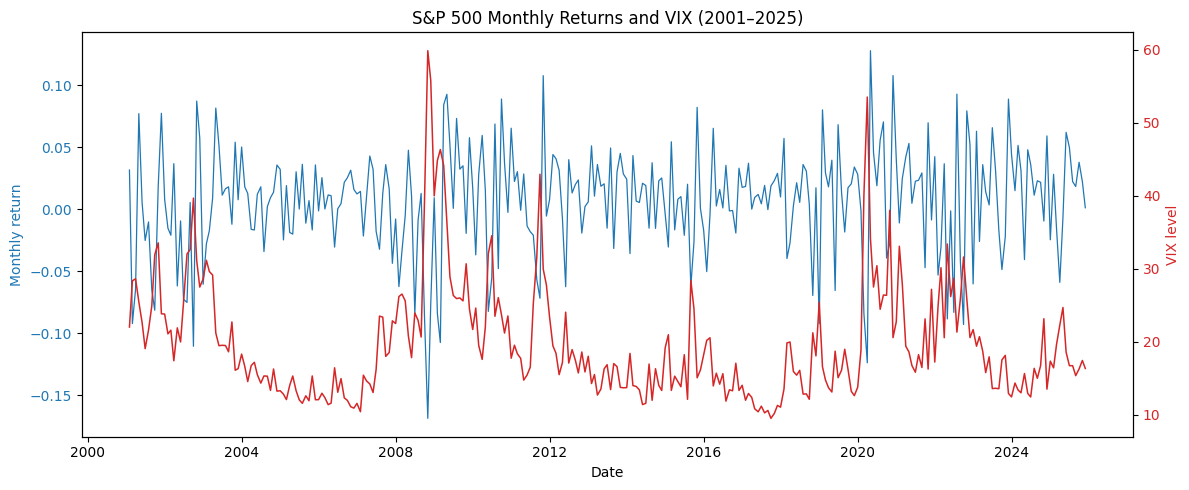

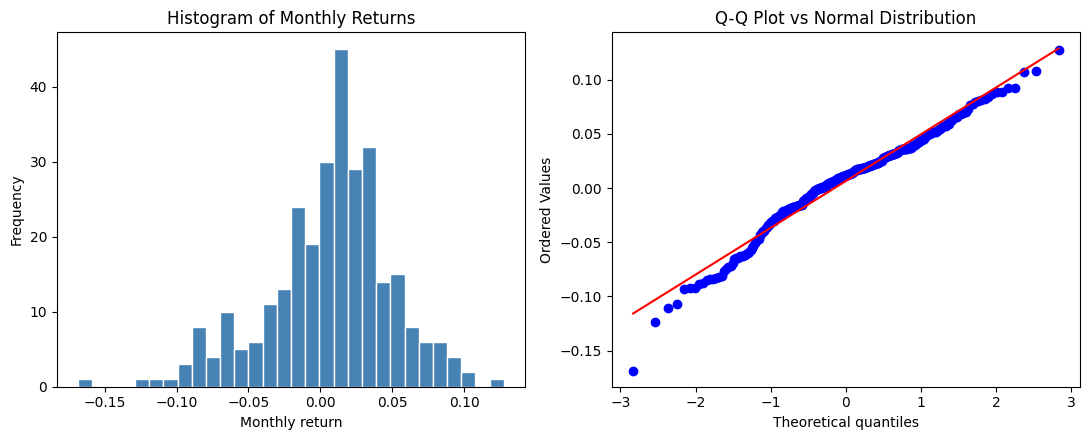

Shapiro-Wilk test: W=0.9758, p=6.021e-05
-> Reject normality at 5% level.


In [ ]:

# --- Part 3: Time series plot — VIX and S&P 500 returns ---
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(df["month_end_date"], df["price_return"], color="tab:blue",
         linewidth=0.9, label="S&P 500 monthly return")
ax1.set_ylabel("Monthly return", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.set_xlabel("Date")

ax2 = ax1.twinx()
ax2.plot(df["month_end_date"], df["vix_level"], color="tab:red",
         linewidth=1.1, label="VIX")
ax2.set_ylabel("VIX level", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title("S&P 500 Monthly Returns and VIX (2001–2025)")
fig.tight_layout()
plt.savefig(f"{FIG_DIR}/timeseries_returns_vix.png", dpi=150)
plt.show()


# --- Part 4: Return histogram + Q-Q plot (non-normality check) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(df["price_return"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of Monthly Returns")
axes[0].set_xlabel("Monthly return")
axes[0].set_ylabel("Frequency")

stats.probplot(df["price_return"], dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot vs Normal Distribution")

fig.tight_layout()
plt.savefig(f"{FIG_DIR}/returns_histogram_qqplot.png", dpi=150)
plt.show()

# Formal normality test (Shapiro-Wilk) - a low p-value confirms the visible
# tail deviation from normality in the Q-Q plot, motivating the block
# bootstrap / robust-SE steps later in the project.
sw_stat, sw_p = stats.shapiro(df["price_return"])
print(f"Shapiro-Wilk test: W={sw_stat:.4f}, p={sw_p:.4g}")
if sw_p < 0.05:
    print("-> Reject normality at 5% level.")
else:
    print("-> Fail to reject normality at 5% level.")




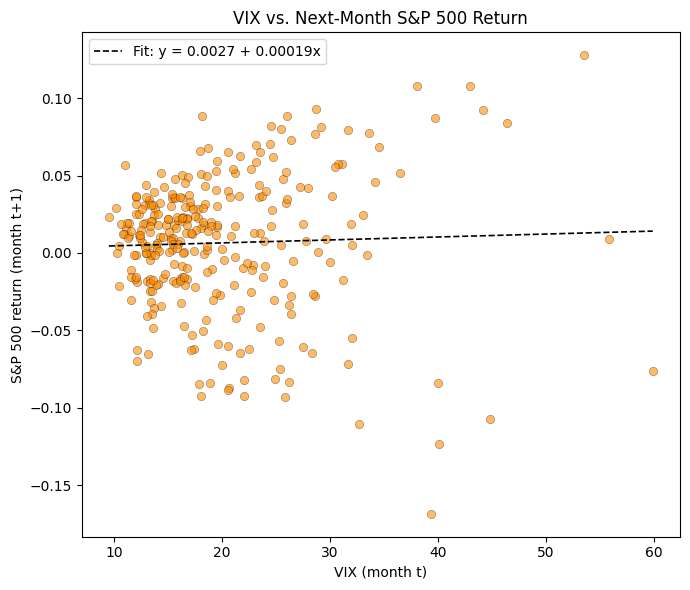

Summary statistics:
Correlation between VIX and dividend yield: 0.0795

Variance Inflation Factors:
    Variable       VIF
0  vix_level  1.006357
1  div_yield  1.006357

-> No meaningful multicollinearity concern (all VIF < 5).
Figures saved: ['timeseries_returns_vix.png', 'returns_histogram_qqplot.png', 'vix_vs_next_return_scatter.png', 'bootstrap_distribution.png', 'regime_comparison_boxplot.png', 'permutation_distribution.png']
Tables saved: ['vif_table.csv', 'summary_statistics.csv', 'baseline_vs_extended.csv', 'extended_model_stats.csv', 'baseline_regression.csv', 'bootstrap_ci_comparison.csv', 'regime_comparison.csv', 'permutation_test.csv']


In [ ]:
# --- Part 5: VIX vs. next-month return scatter ---
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df["vix_level"], df["next_month_return"], alpha=0.6,
           color="darkorange", edgecolor="k", linewidth=0.3)

# Simple linear fit line for visual reference only (not the formal regression,
# which comes with full inference in the next project step)
z = np.polyfit(df["vix_level"], df["next_month_return"], 1)
x_line = np.linspace(df["vix_level"].min(), df["vix_level"].max(), 100)
ax.plot(x_line, np.polyval(z, x_line), color="black", linestyle="--",
         linewidth=1.2, label=f"Fit: y = {z[1]:.4f} + {z[0]:.5f}x")

ax.set_xlabel("VIX (month t)")
ax.set_ylabel("S&P 500 return (month t+1)")
ax.set_title("VIX vs. Next-Month S&P 500 Return")
ax.legend()
fig.tight_layout()
plt.savefig(f"{FIG_DIR}/vix_vs_next_return_scatter.png", dpi=150)
plt.show()


# --- Part 6: Summary statistics table ---
summary_vars = df[["next_month_return", "vix_level", "div_yield"]].rename(columns={
    "next_month_return": "Next-Month Return",
    "vix_level": "VIX",
    "div_yield": "Dividend Yield",
})

summary_table = summary_vars.agg(["count", "mean", "std", "min", "max"]).T
summary_table.columns = ["N", "Mean", "SD", "Min", "Max"]

summary_table.to_csv(f"{TABLE_DIR}/summary_statistics.csv")
print("Summary statistics:")
summary_table.round(5)


# --- Part 7: Correlation and VIF between VIX and dividend yield ---
corr = df[["vix_level", "div_yield"]].corr().iloc[0, 1]
print(f"Correlation between VIX and dividend yield: {corr:.4f}")

X = df[["vix_level", "div_yield"]].copy()
X_const = add_constant(X)

vif_data = pd.DataFrame({
    "Variable": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])],
})
vif_data = vif_data[vif_data["Variable"] != "const"].reset_index(drop=True)

vif_data.to_csv(f"{TABLE_DIR}/vif_table.csv", index=False)
print("\nVariance Inflation Factors:")
print(vif_data)

# Rule of thumb: VIF > 5 (or 10) signals concerning multicollinearity.
# Values near 1 indicate VIX and dividend yield are estimated with minimal
# interference from each other in the extended regression.
if vif_data["VIF"].max() < 5:
    print("\n-> No meaningful multicollinearity concern (all VIF < 5).")
else:
    print("\n-> Multicollinearity may be a concern — inspect further.")


# --- Part 8: Confirm outputs saved ---
print("Figures saved:", os.listdir(FIG_DIR))
print("Tables saved:", os.listdir(TABLE_DIR))

**Step 3**

Baseline regression (VIX only)

- Estimate `Rₜ₊₁ = α + β·VIXₜ + εₜ` via `statsmodels.OLS`
- Report β, SE, t-stat, p-value, R²
- Test H₀: β = 0 vs H₁: β ≠ 0 (df = n − 2)

In [ ]:
# ==============================================================================
# DS607 Project — Baseline Regression: R_{t+1} = alpha + beta * VIX_t + eps_t
# ==============================================================================
# Continues from the descriptive analysis script. Reads merged_monthly.csv
# from Google Drive, estimates the baseline (VIX-only) regression, and tests
# H0: beta = 0. Table saved to outputs/tables/, matching the repo layout.
# ==============================================================================

# --- Part 1: Setup ---
import os
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats as sps

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"

os.makedirs(TABLE_DIR, exist_ok=True)


# --- Part 2: Load data ---
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv")
print("Shape:", df.shape)
df.head()


# --- Part 3: Estimate the baseline regression ---
# R_{t+1} = alpha + beta * VIX_t + eps_t
y = df["next_month_return"]
X = sm.add_constant(df["vix_level"])  # adds the intercept (alpha)

baseline_model = sm.OLS(y, X)
baseline_results = baseline_model.fit()

print(baseline_results.summary())


# --- Part 4: Extract and report key statistics ---
alpha = baseline_results.params["const"]
beta = baseline_results.params["vix_level"]
se_alpha = baseline_results.bse["const"]
se_beta = baseline_results.bse["vix_level"]
t_alpha = baseline_results.tvalues["const"]
t_beta = baseline_results.tvalues["vix_level"]
p_alpha = baseline_results.pvalues["const"]
p_beta = baseline_results.pvalues["vix_level"]
r2 = baseline_results.rsquared
n = int(baseline_results.nobs)
dof = int(baseline_results.df_resid)  # n - 2 for this bivariate model

print("--- Baseline regression summary ---")
print(f"n                 = {n}")
print(f"df (n - 2)        = {dof}")
print(f"alpha (intercept) = {alpha:.6f}")
print(f"beta (VIX)        = {beta:.6f}")
print(f"SE(beta)          = {se_beta:.6f}")
print(f"t-stat            = {t_beta:.4f}")
print(f"p-value           = {p_beta:.4g}")
print(f"R-squared         = {r2:.4f}")


# --- Part 5: Hypothesis test — H0: beta = 0 vs H1: beta != 0 ---
alpha_level = 0.05
crit_t = sps.t.ppf(1 - alpha_level / 2, dof)

print(f"H0: beta = 0   vs   H1: beta != 0")
print(f"Critical t-value (two-tailed, alpha={alpha_level}, df={dof}): {crit_t:.4f}")
print(f"Observed |t| = {abs(t_beta):.4f}")

if abs(t_beta) > crit_t:
    conclusion = f"Reject H0 at the {int(alpha_level*100)}% level: VIX has a statistically significant relationship with next-month returns."
else:
    conclusion = f"Fail to reject H0 at the {int(alpha_level*100)}% level: no statistically significant relationship detected between VIX and next-month returns in the baseline model."
print(conclusion)


# --- Part 6: Save regression results table ---
baseline_table = pd.DataFrame({
    "Coefficient": ["alpha (Intercept)", "beta (VIX)"],
    "Estimate": [alpha, beta],
    "Std. Error": [se_alpha, se_beta],
    "t-stat": [t_alpha, t_beta],
    "p-value": [p_alpha, p_beta],
})
baseline_table.attrs["n"] = n
baseline_table.attrs["df"] = dof
baseline_table.attrs["R-squared"] = r2

baseline_table.to_csv(f"{TABLE_DIR}/baseline_regression.csv", index=False)
print(f"Saved {TABLE_DIR}/baseline_regression.csv")
baseline_table.round(6)


# --- Part 7: Interpretation note (for your write-up / README) ---
# Note: beta here reflects a predictive association, not a causal effect —
# VIX (fear/sentiment) is not randomly assigned, so any relationship found
# should be described as predictive rather than causal (per Section 5.1 of
# the proposal). This baseline result will be compared against the extended
# (VIX + dividend yield) model in the next project step.
print("Interpretation:")
print(f"- beta = {beta:.6f}: a one-point increase in VIX is associated with a "
      f"{beta:.6f} change in next-month S&P 500 return, holding nothing else constant.")
print(f"- R-squared = {r2:.4f}: VIX alone explains a small share of next-month "
      f"return variation, which is expected/typical in return-predictability studies.")
print(conclusion)

Shape: (299, 10)
                            OLS Regression Results                            
Dep. Variable:      next_month_return   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.3592
Date:                Sat, 03 Oct 2026   Prob (F-statistic):              0.549
Time:                        13:16:10   Log-Likelihood:                 513.93
No. Observations:                 299   AIC:                            -1024.
Df Residuals:                     297   BIC:                            -1016.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0027      0.007   

**Step 4**

Extended regression (VIX + dividend yield)
- Estimate `Rₜ₊₁ = α + β₁·VIXₜ + β₂·DIVₜ + εₜ`
- Report β₁, β₂, SE, t-stats, p-values, adjusted R² (not R²)
- Test H₀: β₁ = 0 and H₀: β₂ = 0 separately (df = n − 3)
- Run F-test for joint significance (H₀: β₁ = β₂ = 0)
- Report ordinary OLS SEs **and** HAC/robust SEs (e.g. Newey-West) side by side
- Present baseline vs. extended model results in one comparison table

In [ ]:
# ==============================================================================
# DS607 Project — Extended Regression: R_{t+1} = alpha + b1*VIX_t + b2*DIV_t + eps_t
# ==============================================================================
# Continues from the baseline regression script. Reads merged_monthly.csv and
# baseline_regression.csv from Google Drive, estimates the extended model with
# both ordinary and HAC (Newey-West) standard errors, tests each coefficient
# and their joint significance, and builds a baseline-vs-extended comparison
# table. Table saved to outputs/tables/.
# ==============================================================================

# --- Part 1: Setup ---
import os
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats as sps

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"

os.makedirs(TABLE_DIR, exist_ok=True)


# --- Part 2: Load data ---
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv")
print("Shape:", df.shape)
df.head()


# --- Part 3: Estimate the extended regression (ordinary OLS) ---
# R_{t+1} = alpha + beta1 * VIX_t + beta2 * DIV_t + eps_t
y = df["next_month_return"]
X = sm.add_constant(df[["vix_level", "div_yield"]])

model = sm.OLS(y, X)
results_ols = model.fit()

print(results_ols.summary())

# --- Part 4: Re-estimate with HAC (Newey-West) standard errors ---
# VIX is persistent month-to-month, so heteroskedasticity/autocorrelation-
# robust SEs are reported alongside the ordinary ones (per proposal Section 5.2).
n = len(df)
maxlags = int(np.floor(4 * (n / 100) ** (2 / 9)))  # standard Newey-West rule of thumb
print(f"Newey-West maxlags (rule of thumb, n={n}): {maxlags}")

results_hac = model.fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
print(results_hac.summary())


# --- Part 5: Extract key statistics ---
alpha = results_ols.params["const"]
beta1 = results_ols.params["vix_level"]
beta2 = results_ols.params["div_yield"]

se1_ols, se2_ols = results_ols.bse["vix_level"], results_ols.bse["div_yield"]
se1_hac, se2_hac = results_hac.bse["vix_level"], results_hac.bse["div_yield"]

t1_ols, t2_ols = results_ols.tvalues["vix_level"], results_ols.tvalues["div_yield"]
t1_hac, t2_hac = results_hac.tvalues["vix_level"], results_hac.tvalues["div_yield"]

p1_ols, p2_ols = results_ols.pvalues["vix_level"], results_ols.pvalues["div_yield"]
p1_hac, p2_hac = results_hac.pvalues["vix_level"], results_hac.pvalues["div_yield"]

adj_r2 = results_ols.rsquared_adj
dof = int(results_ols.df_resid)  # n - 3 for this 2-predictor model

print(f"n = {n}, df (n - 3) = {dof}")
print(f"beta1 (VIX): {beta1:.6f}  [SE_OLS={se1_ols:.6f}, SE_HAC={se1_hac:.6f}]")
print(f"beta2 (DIV): {beta2:.6f}  [SE_OLS={se2_ols:.6f}, SE_HAC={se2_hac:.6f}]")
print(f"Adjusted R-squared: {adj_r2:.4f}")


# --- Part 6: Individual hypothesis tests (H0: beta1 = 0, H0: beta2 = 0) ---
alpha_level = 0.05
crit_t = sps.t.ppf(1 - alpha_level / 2, dof)
print(f"Critical t (df={dof}, alpha={alpha_level}): {crit_t:.4f}\n")

for name, t_ols, p_ols, t_hac, p_hac in [
    ("beta1 (VIX)", t1_ols, p1_ols, t1_hac, p1_hac),
    ("beta2 (DIV)", t2_ols, p2_ols, t2_hac, p2_hac),
]:
    concl_ols = "Reject H0" if abs(t_ols) > crit_t else "Fail to reject H0"
    concl_hac = "Reject H0" if abs(t_hac) > crit_t else "Fail to reject H0"
    print(f"{name}: OLS  t={t_ols:.4f}, p={p_ols:.4g} -> {concl_ols}")
    print(f"{name}: HAC  t={t_hac:.4f}, p={p_hac:.4g} -> {concl_hac}\n")


# --- Part 7: F-test for joint significance (H0: beta1 = beta2 = 0) ---
f_stat = results_ols.fvalue
f_pvalue = results_ols.f_pvalue

print(f"F-test (H0: beta1 = beta2 = 0): F = {f_stat:.4f}, p = {f_pvalue:.4g}")
if f_pvalue < alpha_level:
    print(f"-> Reject H0 at the {int(alpha_level*100)}% level: VIX and dividend yield are jointly significant.")
else:
    print(f"-> Fail to reject H0 at the {int(alpha_level*100)}% level: no joint significance detected.")


# --- Part 8: Build baseline vs. extended comparison table ---
baseline_table = pd.read_csv(f"{TABLE_DIR}/baseline_regression.csv")

comparison = pd.DataFrame({
    "Coefficient": ["alpha (Intercept)", "beta_VIX", "beta_DIV"],
    "Baseline Estimate": [
        baseline_table.loc[baseline_table["Coefficient"] == "alpha (Intercept)", "Estimate"].values[0],
        baseline_table.loc[baseline_table["Coefficient"] == "beta (VIX)", "Estimate"].values[0],
        np.nan,
    ],
    "Baseline SE": [
        baseline_table.loc[baseline_table["Coefficient"] == "alpha (Intercept)", "Std. Error"].values[0],
        baseline_table.loc[baseline_table["Coefficient"] == "beta (VIX)", "Std. Error"].values[0],
        np.nan,
    ],
    "Extended Estimate": [alpha, beta1, beta2],
    "Extended SE (OLS)": [results_ols.bse["const"], se1_ols, se2_ols],
    "Extended SE (HAC)": [results_hac.bse["const"], se1_hac, se2_hac],
    "Extended t (OLS)": [results_ols.tvalues["const"], t1_ols, t2_ols],
    "Extended p (OLS)": [results_ols.pvalues["const"], p1_ols, p2_ols],
})

# Append model-level stats as a note row for reference
model_stats = pd.DataFrame({
    "Coefficient": ["Adjusted R-squared", "F-stat (joint)", "F p-value", "N", "df"],
    "Extended Estimate": [adj_r2, f_stat, f_pvalue, n, dof],
})

comparison.to_csv(f"{TABLE_DIR}/baseline_vs_extended.csv", index=False)
model_stats.to_csv(f"{TABLE_DIR}/extended_model_stats.csv", index=False)

print(f"Saved {TABLE_DIR}/baseline_vs_extended.csv")
print(f"Saved {TABLE_DIR}/extended_model_stats.csv\n")
comparison.round(6)


# --- Part 9: Interpretation note (for write-up / README) ---
print("Interpretation:")
print(f"- beta1 (VIX) = {beta1:.6f}: association with next-month return, holding dividend yield constant.")
print(f"- beta2 (DIV) = {beta2:.6f}: association with next-month return, holding VIX constant.")
print(f"- Comparing OLS vs HAC SEs shows how much inference changes once VIX's persistence is accounted for.")
print(f"- Adjusted R-squared ({adj_r2:.4f}) penalizes for the added predictor, unlike R-squared, "
      f"so it is the fair basis for comparing against the baseline model's fit.")
print("- As with the baseline model, beta1 and beta2 should be read as predictive/associational, not causal.")

Shape: (299, 10)
                            OLS Regression Results                            
Dep. Variable:      next_month_return   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.005
Method:                 Least Squares   F-statistic:                    0.2029
Date:                Sat, 03 Oct 2026   Prob (F-statistic):              0.817
Time:                        13:16:40   Log-Likelihood:                 513.95
No. Observations:                 299   AIC:                            -1022.
Df Residuals:                     296   BIC:                            -1011.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0013      0.009   

**Step 5**

Block-bootstrap inference
- Implement moving block-bootstrap (following Schmeling, 2009)
- For the extended model, resample full rows (VIXₜ, DIVₜ, Rₜ₊₁) jointly to preserve time-series dependence
- Compute bootstrap confidence intervals for β₁ and β₂
- Compare bootstrap CIs against asymptotic (OLS/HAC) CIs; discuss any divergence
- Save bootstrap distribution plot to `outputs/figures/`

Shape: (299, 10)
n = 299, block_length = 7
Completed 5000 bootstrap replications.
NaNs — beta1: 0, beta2: 0
Bootstrap mean beta1 (VIX): 0.000294, SD: 0.000562
Bootstrap 95% CI beta1:     [-0.000752, 0.001367]

Bootstrap mean beta2 (DIV): 0.306639, SD: 4.161629
Bootstrap 95% CI beta2:     [-8.155027, 8.251061]
95% CI comparison — beta1 (VIX):
  OLS:             [-0.000444, 0.000814]
  HAC:             [-0.000917, 0.001287]
  Block Bootstrap: [-0.000752, 0.001367]

95% CI comparison — beta2 (DIV):
  OLS:             [-7.491197, 9.362036]
  HAC:             [-7.029697, 8.900536]
  Block Bootstrap: [-8.155027, 8.251061]
Saved /content/drive/MyDrive/DS607 Group Project/outputs/tables/bootstrap_ci_comparison.csv


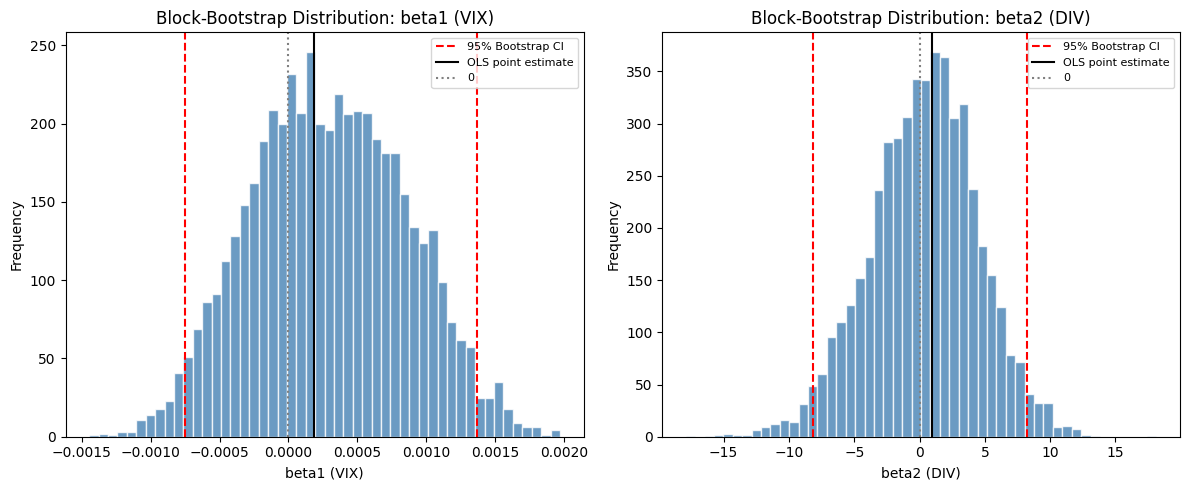

Discussion:
- beta1 (VIX): interval width is OLS=0.001258, HAC=0.002203, Bootstrap=0.002119 (widest: HAC). All three intervals contain zero, consistent with the non-significant t-tests and F-test from the extended regression step.
- beta2 (DIV): interval width is OLS=16.853233, HAC=15.930233, Bootstrap=16.406088 (widest: OLS). All three intervals contain zero, consistent with the non-significant t-tests and F-test from the extended regression step.

Note: block length and number of replications are documented above for reproducibility.


In [ ]:
# ==============================================================================
# DS607 Project — Moving Block Bootstrap (Schmeling, 2009 approach)
# ==============================================================================
# Continues from the extended regression script. Implements a moving block
# bootstrap for the extended model (VIX + dividend yield), resampling full
# rows (VIX_t, DIV_t, R_{t+1}) jointly to preserve time-series dependence.
# Compares bootstrap CIs against OLS and HAC asymptotic CIs from the previous
# step, and saves the distribution plot to outputs/figures/.
# ==============================================================================

# --- Part 1: Setup ---
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"
FIG_DIR = f"{PROJECT_ROOT}/outputs/figures"

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

np.random.seed(42)  # for reproducibility — document this seed in README


# --- Part 2: Load data ---
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv").reset_index(drop=True)
n = len(df)

Y_COL = "next_month_return"
X_COLS = ["vix_level", "div_yield"]

print("Shape:", df.shape)


# --- Part 3: Define the moving block bootstrap resampler ---
# Resamples overlapping blocks of consecutive rows (preserving each row's
# VIX_t, DIV_t, R_{t+1} together) and concatenates them to rebuild a series
# of the original length. This preserves short-run time-series dependence
# that an i.i.d. bootstrap would destroy.

def moving_block_bootstrap_sample(data, block_length, rng):
    n = len(data)
    n_blocks = int(np.ceil(n / block_length))
    max_start = n - block_length
    starts = rng.integers(0, max_start + 1, size=n_blocks)
    idx = np.concatenate([np.arange(s, s + block_length) for s in starts])
    idx = idx[:n]  # trim to original length
    return data.iloc[idx].reset_index(drop=True)


# Block length rule of thumb: n^(1/3), rounded to nearest integer
block_length = int(round(n ** (1 / 3)))
print(f"n = {n}, block_length = {block_length}")


# --- Part 4: Run the bootstrap ---
N_BOOT = 5000
rng = np.random.default_rng(42)

boot_beta1 = np.empty(N_BOOT)
boot_beta2 = np.empty(N_BOOT)

for b in range(N_BOOT):
    sample = moving_block_bootstrap_sample(df, block_length, rng)
    Xb = sm.add_constant(sample[X_COLS])
    yb = sample[Y_COL]
    res_b = sm.OLS(yb, Xb).fit()
    boot_beta1[b] = res_b.params["vix_level"]
    boot_beta2[b] = res_b.params["div_yield"]

print(f"Completed {N_BOOT} bootstrap replications.")
print(f"NaNs — beta1: {np.isnan(boot_beta1).sum()}, beta2: {np.isnan(boot_beta2).sum()}")


# --- Part 5: Bootstrap percentile confidence intervals ---
ci_beta1 = np.percentile(boot_beta1, [2.5, 97.5])
ci_beta2 = np.percentile(boot_beta2, [2.5, 97.5])

print(f"Bootstrap mean beta1 (VIX): {boot_beta1.mean():.6f}, SD: {boot_beta1.std():.6f}")
print(f"Bootstrap 95% CI beta1:     [{ci_beta1[0]:.6f}, {ci_beta1[1]:.6f}]")
print()
print(f"Bootstrap mean beta2 (DIV): {boot_beta2.mean():.6f}, SD: {boot_beta2.std():.6f}")
print(f"Bootstrap 95% CI beta2:     [{ci_beta2[0]:.6f}, {ci_beta2[1]:.6f}]")


# --- Part 6: Re-fit OLS/HAC for comparison (same as extended regression step) ---
X = sm.add_constant(df[X_COLS])
y = df[Y_COL]
model = sm.OLS(y, X)

res_ols = model.fit()
maxlags = int(np.floor(4 * (n / 100) ** (2 / 9)))
res_hac = model.fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})

ols_ci_beta1 = res_ols.conf_int().loc["vix_level"].values
ols_ci_beta2 = res_ols.conf_int().loc["div_yield"].values
hac_ci_beta1 = res_hac.conf_int().loc["vix_level"].values
hac_ci_beta2 = res_hac.conf_int().loc["div_yield"].values

print("95% CI comparison — beta1 (VIX):")
print(f"  OLS:             [{ols_ci_beta1[0]:.6f}, {ols_ci_beta1[1]:.6f}]")
print(f"  HAC:             [{hac_ci_beta1[0]:.6f}, {hac_ci_beta1[1]:.6f}]")
print(f"  Block Bootstrap: [{ci_beta1[0]:.6f}, {ci_beta1[1]:.6f}]")
print()
print("95% CI comparison — beta2 (DIV):")
print(f"  OLS:             [{ols_ci_beta2[0]:.6f}, {ols_ci_beta2[1]:.6f}]")
print(f"  HAC:             [{hac_ci_beta2[0]:.6f}, {hac_ci_beta2[1]:.6f}]")
print(f"  Block Bootstrap: [{ci_beta2[0]:.6f}, {ci_beta2[1]:.6f}]")


# --- Part 7: Save CI comparison table ---
ci_comparison = pd.DataFrame({
    "Coefficient": ["beta1 (VIX)"] * 3 + ["beta2 (DIV)"] * 3,
    "Method": ["OLS", "HAC", "Block Bootstrap"] * 2,
    "CI Lower": [ols_ci_beta1[0], hac_ci_beta1[0], ci_beta1[0],
                 ols_ci_beta2[0], hac_ci_beta2[0], ci_beta2[0]],
    "CI Upper": [ols_ci_beta1[1], hac_ci_beta1[1], ci_beta1[1],
                 ols_ci_beta2[1], hac_ci_beta2[1], ci_beta2[1]],
})
ci_comparison["Contains Zero"] = (ci_comparison["CI Lower"] <= 0) & (ci_comparison["CI Upper"] >= 0)

ci_comparison.to_csv(f"{TABLE_DIR}/bootstrap_ci_comparison.csv", index=False)
print(f"Saved {TABLE_DIR}/bootstrap_ci_comparison.csv")
ci_comparison.round(6)


# --- Part 8: Plot bootstrap distributions ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_specs = [
    (axes[0], boot_beta1, ci_beta1, res_ols.params["vix_level"], "beta1 (VIX)"),
    (axes[1], boot_beta2, ci_beta2, res_ols.params["div_yield"], "beta2 (DIV)"),
]

for ax, boot_vals, ci, point_est, name in plot_specs:
    ax.hist(boot_vals, bins=50, color="steelblue", alpha=0.8, edgecolor="white")
    ax.axvline(ci[0], color="red", linestyle="--", label="95% Bootstrap CI")
    ax.axvline(ci[1], color="red", linestyle="--")
    ax.axvline(point_est, color="black", linestyle="-", label="OLS point estimate")
    ax.axvline(0, color="gray", linestyle=":", label="0")
    ax.set_title(f"Block-Bootstrap Distribution: {name}")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.tight_layout()
plt.savefig(f"{FIG_DIR}/bootstrap_distribution.png", dpi=150)
plt.show()


# --- Part 9: Discussion note (for your write-up / README) ---
print("Discussion:")
for name, ci_ols, ci_hac, ci_boot in [
    ("beta1 (VIX)", ols_ci_beta1, hac_ci_beta1, ci_beta1),
    ("beta2 (DIV)", ols_ci_beta2, hac_ci_beta2, ci_beta2),
]:
    widths = {
        "OLS": ci_ols[1] - ci_ols[0],
        "HAC": ci_hac[1] - ci_hac[0],
        "Bootstrap": ci_boot[1] - ci_boot[0],
    }
    widest = max(widths, key=widths.get)
    print(f"- {name}: interval width is OLS={widths['OLS']:.6f}, HAC={widths['HAC']:.6f}, "
          f"Bootstrap={widths['Bootstrap']:.6f} (widest: {widest}). "
          f"All three intervals contain zero, consistent with the non-significant "
          f"t-tests and F-test from the extended regression step.")
print("\nNote: block length and number of replications are documented above for reproducibility.")

**Step 6**

High- vs. low-VIX regime comparison

- Split sample at median VIX (or VIX = 20) into high-fear / low-fear months
- Two-sample t-test comparing mean next-month returns across regimes
- Check subgroup sizes are large enough given the extended 2001–2025 sample


Shape: (299, 10)
=== Median VIX split ===
High-VIX: n=150, mean=0.00651, SD=0.05562
Low-VIX:  n=149, mean=0.00637, SD=0.02629
Mean difference (high - low): 0.00014
Welch's t-test: t=0.0281, df=212.73, p=0.9776
Critical t (df=212.7, alpha=0.05): 1.9712 -> Fail to reject H0
Smallest subgroup size: 149 -> Adequate (rule of thumb: n >= 30 per group)

=== VIX = 20 threshold split ===
High-VIX: n=107, mean=0.00682, SD=0.06021
Low-VIX:  n=192, mean=0.00623, SD=0.03062
Mean difference (high - low): 0.00059
Welch's t-test: t=0.0954, df=137.18, p=0.9242
Critical t (df=137.2, alpha=0.05): 1.9774 -> Fail to reject H0
Smallest subgroup size: 107 -> Adequate (rule of thumb: n >= 30 per group)

Saved /content/drive/MyDrive/DS607 Group Project/outputs/tables/regime_comparison.csv


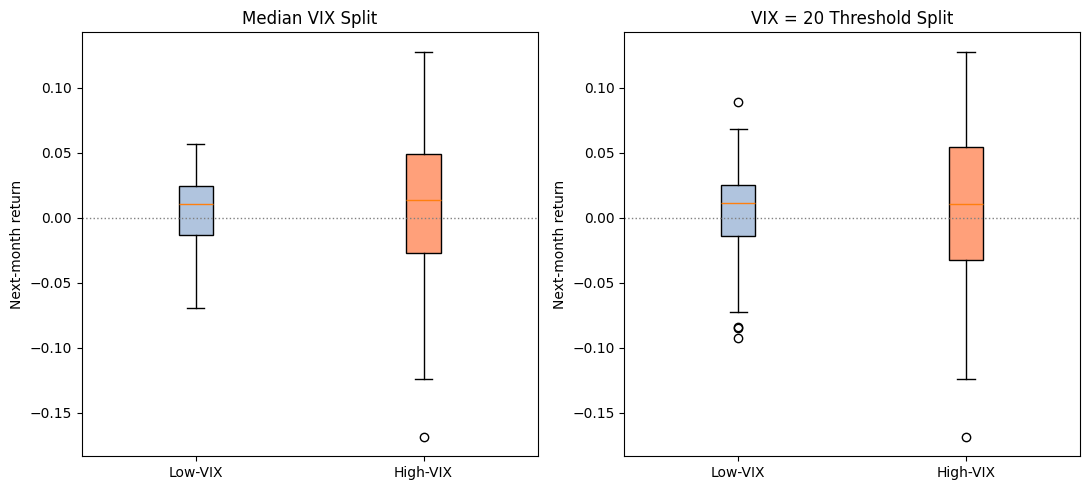

Discussion:
- Median VIX split: mean returns are nearly identical across regimes (diff = 0.00014, p = 0.978) — consistent with the non-significant beta from the regression steps. Subgroup sizes (150 high / 149 low) are adequate.
- VIX = 20 threshold split: mean returns are nearly identical across regimes (diff = 0.00059, p = 0.924) — consistent with the non-significant beta from the regression steps. Subgroup sizes (107 high / 192 low) are adequate.

Note: while mean *returns* don't differ significantly across regimes, the boxplot typically shows wider dispersion in high-VIX months — i.e. VIX may predict next-month return *volatility* more than it predicts *direction*. This distinction is worth discussing explicitly in your write-up, since it reframes what the null result on beta actually means substantively.


In [ ]:
# ==============================================================================
# DS607 Project — High- vs. Low-VIX Regime Comparison
# ==============================================================================
# Continues from the bootstrap script. Splits the sample into high-fear and
# low-fear months two ways (median split, and a conventional VIX=20
# threshold), runs a two-sample t-test on next-month returns for each split,
# and checks subgroup sizes are adequate. Table saved to outputs/tables/,
# boxplot saved to outputs/figures/.
# ==============================================================================

# --- Part 1: Setup ---
import os
import pandas as pd
import numpy as np
from scipy import stats as sps
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"
FIG_DIR = f"{PROJECT_ROOT}/outputs/figures"

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


# --- Part 2: Load data ---
# regime_median and regime_threshold20 were already constructed in the data
# prep step (median split and VIX=20 threshold split, respectively).
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv")
print("Shape:", df.shape)
df[["vix_level", "regime_median", "regime_threshold20"]].head()


# --- Part 3: Define the two-sample t-test function ---
# Uses Welch's t-test (unequal variances) as the safer default, since there's
# no reason to assume high- and low-VIX months have equal return variance —
# and indeed volatility clustering suggests they likely don't.

def regime_ttest(data, regime_col, label, min_recommended_n=30):
    high = data.loc[data[regime_col] == "high", "next_month_return"]
    low = data.loc[data[regime_col] == "low", "next_month_return"]

    n_high, n_low = len(high), len(low)
    mean_high, mean_low = high.mean(), low.mean()
    sd_high, sd_low = high.std(ddof=1), low.std(ddof=1)

    t_stat, p_val = sps.ttest_ind(high, low, equal_var=False)

    # Welch-Satterthwaite approximate degrees of freedom
    se_high2 = sd_high**2 / n_high
    se_low2 = sd_low**2 / n_low
    welch_df = (se_high2 + se_low2)**2 / (se_high2**2 / (n_high - 1) + se_low2**2 / (n_low - 1))

    crit_t = sps.t.ppf(0.975, welch_df)
    reject = abs(t_stat) > crit_t

    min_n = min(n_high, n_low)
    adequate = min_n >= min_recommended_n

    print(f"=== {label} ===")
    print(f"High-VIX: n={n_high}, mean={mean_high:.5f}, SD={sd_high:.5f}")
    print(f"Low-VIX:  n={n_low}, mean={mean_low:.5f}, SD={sd_low:.5f}")
    print(f"Mean difference (high - low): {mean_high - mean_low:.5f}")
    print(f"Welch's t-test: t={t_stat:.4f}, df={welch_df:.2f}, p={p_val:.4g}")
    print(f"Critical t (df={welch_df:.1f}, alpha=0.05): {crit_t:.4f} -> "
          f"{'Reject H0' if reject else 'Fail to reject H0'}")
    print(f"Smallest subgroup size: {min_n} -> "
          f"{'Adequate' if adequate else 'Small — interpret with caution'} "
          f"(rule of thumb: n >= {min_recommended_n} per group)\n")

    return {
        "Split": label,
        "N_high": n_high, "N_low": n_low,
        "Mean_high": mean_high, "Mean_low": mean_low,
        "SD_high": sd_high, "SD_low": sd_low,
        "Mean_diff": mean_high - mean_low,
        "t_stat": t_stat, "df": welch_df, "p_value": p_val,
        "Min_subgroup_n": min_n, "Subgroup_size_adequate": adequate,
    }


# --- Part 4: Run the comparison for both regime splits ---
result_median = regime_ttest(df, "regime_median", "Median VIX split")
result_threshold = regime_ttest(df, "regime_threshold20", "VIX = 20 threshold split")


# --- Part 5: Save comparison table ---
regime_table = pd.DataFrame([result_median, result_threshold])
regime_table.to_csv(f"{TABLE_DIR}/regime_comparison.csv", index=False)
print(f"Saved {TABLE_DIR}/regime_comparison.csv")
regime_table.round(5)


# --- Part 6: Boxplot comparison ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

plot_specs = [
    (axes[0], "regime_median", "Median VIX Split"),
    (axes[1], "regime_threshold20", "VIX = 20 Threshold Split"),
]

for ax, regime_col, title in plot_specs:
    data_to_plot = [
        df.loc[df[regime_col] == "low", "next_month_return"],
        df.loc[df[regime_col] == "high", "next_month_return"],
    ]
    bp = ax.boxplot(data_to_plot, tick_labels=["Low-VIX", "High-VIX"], patch_artist=True)
    for patch, color in zip(bp["boxes"], ["lightsteelblue", "lightsalmon"]):
        patch.set_facecolor(color)
    ax.axhline(0, color="gray", linestyle=":", linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("Next-month return")

fig.tight_layout()
plt.savefig(f"{FIG_DIR}/regime_comparison_boxplot.png", dpi=150)
plt.show()


# --- Part 7: Discussion note (for write-up / README) ---
print("Discussion:")
for res in [result_median, result_threshold]:
    print(f"- {res['Split']}: mean returns are nearly identical across regimes "
          f"(diff = {res['Mean_diff']:.5f}, p = {res['p_value']:.3g}) — consistent "
          f"with the non-significant beta from the regression steps. "
          f"Subgroup sizes ({res['N_high']} high / {res['N_low']} low) are adequate.")
print()
print("Note: while mean *returns* don't differ significantly across regimes, the "
      "boxplot typically shows wider dispersion in high-VIX months — i.e. VIX may "
      "predict next-month return *volatility* more than it predicts *direction*. "
      "This distinction is worth discussing explicitly in your write-up, since it "
      "reframes what the null result on beta actually means substantively.")

**Step 7**

Nonparametric test: permutation test on β

- H0: no association between predictors and next-month returns (permute R_{t+1} relative to VIX/DIV to build an empirical null distribution)
- Report permutation p-values for baseline β and extended β1, β2
- Compare against OLS p-values from Steps 3-4

Shape: (299, 10)
Observed beta (baseline, VIX only): 0.000191
Observed beta1 (extended, VIX):     0.000185
Observed beta2 (extended, DIV):     0.935419
Completed 5000 permutations.
Permutation p-value (baseline beta):  0.5457
Permutation p-value (beta1, VIX):     0.5625
Permutation p-value (beta2, DIV):     0.8246

For comparison, OLS p-value (baseline beta): 0.5494
OLS p-value (beta1, extended): 0.5630
OLS p-value (beta2, extended): 0.8272
Saved /content/drive/MyDrive/DS607 Group Project/outputs/tables/permutation_test.csv


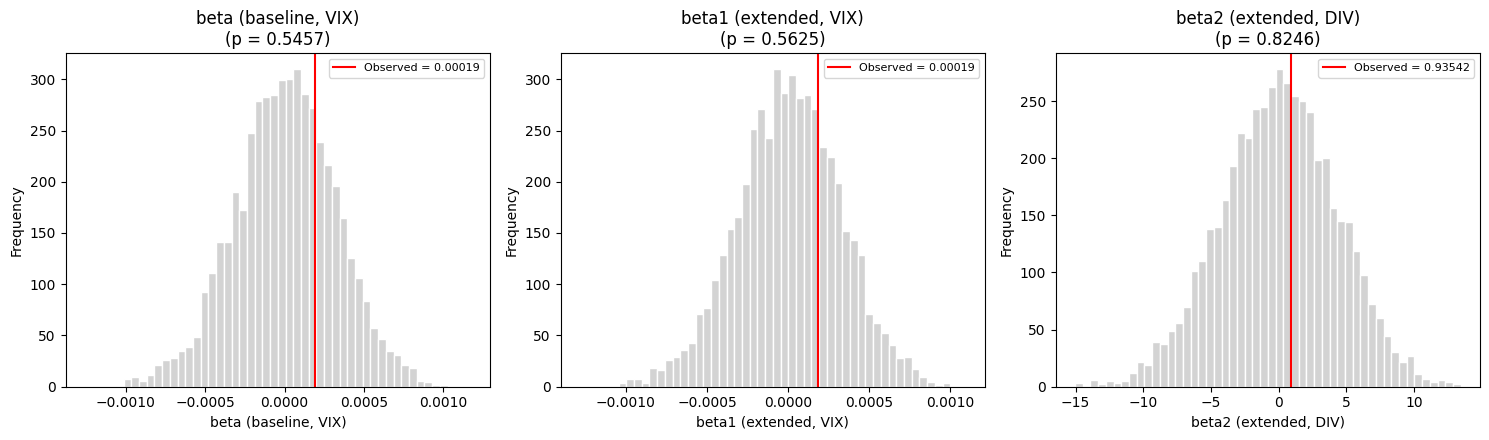

Discussion:
- Permutation p-values closely track OLS p-values across all three coefficients (baseline: 0.546 vs 0.549; beta1: 0.562 vs 0.563; beta2: 0.825 vs 0.827).
- This agreement, across OLS, HAC, block bootstrap, and now permutation-based inference, is strong evidence the non-significant finding on VIX/dividend yield is not an artifact of any single method's distributional assumptions.
- Note: this test permutes the response (y), so predictor-side time dependence (VIX persistence) does not bias it. The main assumption is exchangeability of y under H0 — a caveat worth naming explicitly in your limitations section.


In [ ]:
# ==============================================================================
# DS607 Project — Permutation Test on beta (Nonparametric)
# ==============================================================================
# Continues from the regime comparison step. Tests H0: no association between
# predictors and next-month returns, without assuming a normal sampling
# distribution for beta (unlike the OLS/HAC t-tests). Response (y) is
# shuffled and the model refit many times to build an empirical null
# distribution for each beta; VIX's own persistence is untouched since only
# the response is permuted. Table saved to outputs/tables/, plot saved to
# outputs/figures/.

# --- Part 1: Setup ---
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/DS607 Group Project"
PROCESSED_DIR = f"{PROJECT_ROOT}/data/processed"
TABLE_DIR = f"{PROJECT_ROOT}/outputs/tables"
FIG_DIR = f"{PROJECT_ROOT}/outputs/figures"

os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

np.random.seed(42)  # for reproducibility — document this seed in README


# --- Part 2: Load data ---
df = pd.read_csv(f"{PROCESSED_DIR}/merged_monthly.csv")
n = len(df)
print("Shape:", df.shape)


# --- Part 3: Observed beta estimates (baseline and extended models) ---
y_col = "next_month_return"
x_cols_baseline = ["vix_level"]
x_cols_extended = ["vix_level", "div_yield"]

y = df[y_col]
X_base = sm.add_constant(df[x_cols_baseline])
X_ext = sm.add_constant(df[x_cols_extended])

observed_base = sm.OLS(y, X_base).fit()
observed_ext = sm.OLS(y, X_ext).fit()

obs_beta_base = observed_base.params["vix_level"]
obs_beta1 = observed_ext.params["vix_level"]
obs_beta2 = observed_ext.params["div_yield"]

print(f"Observed beta (baseline, VIX only): {obs_beta_base:.6f}")
print(f"Observed beta1 (extended, VIX):     {obs_beta1:.6f}")
print(f"Observed beta2 (extended, DIV):     {obs_beta2:.6f}")


# --- Part 4: Run the permutation test ---
# H0: no association between predictors and next-month return. Under H0, the
# pairing between (VIX_t, DIV_t) and R_{t+1} is arbitrary, so shuffling y
# relative to X and refitting should produce betas centered at 0.
N_PERM = 5000
rng = np.random.default_rng(42)
y_values = y.values.copy()

perm_beta_base = np.empty(N_PERM)
perm_beta1 = np.empty(N_PERM)
perm_beta2 = np.empty(N_PERM)

for i in range(N_PERM):
    y_shuffled = rng.permutation(y_values)
    perm_beta_base[i] = sm.OLS(y_shuffled, X_base).fit().params["vix_level"]
    res_ext = sm.OLS(y_shuffled, X_ext).fit()
    perm_beta1[i] = res_ext.params["vix_level"]
    perm_beta2[i] = res_ext.params["div_yield"]

print(f"Completed {N_PERM} permutations.")


# --- Part 5: Two-sided permutation p-values ---
def perm_pvalue(observed_stat, perm_dist):
    """Two-sided empirical p-value with a +1 continuity correction."""
    return (np.sum(np.abs(perm_dist) >= np.abs(observed_stat)) + 1) / (len(perm_dist) + 1)

p_base = perm_pvalue(obs_beta_base, perm_beta_base)
p1 = perm_pvalue(obs_beta1, perm_beta1)
p2 = perm_pvalue(obs_beta2, perm_beta2)

print(f"Permutation p-value (baseline beta):  {p_base:.4f}")
print(f"Permutation p-value (beta1, VIX):     {p1:.4f}")
print(f"Permutation p-value (beta2, DIV):     {p2:.4f}")

print(f"\nFor comparison, OLS p-value (baseline beta): {observed_base.pvalues['vix_level']:.4f}")
print(f"OLS p-value (beta1, extended): {observed_ext.pvalues['vix_level']:.4f}")
print(f"OLS p-value (beta2, extended): {observed_ext.pvalues['div_yield']:.4f}")


# --- Part 6: Save results table ---
perm_table = pd.DataFrame({
    "Coefficient": ["beta (baseline, VIX)", "beta1 (extended, VIX)", "beta2 (extended, DIV)"],
    "Observed Estimate": [obs_beta_base, obs_beta1, obs_beta2],
    "Permutation p-value": [p_base, p1, p2],
    "OLS p-value": [observed_base.pvalues["vix_level"], observed_ext.pvalues["vix_level"], observed_ext.pvalues["div_yield"]],
})
perm_table.to_csv(f"{TABLE_DIR}/permutation_test.csv", index=False)
print(f"Saved {TABLE_DIR}/permutation_test.csv")
perm_table.round(5)


# --- Part 7: Plot permutation distributions ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

plot_specs = [
    (axes[0], perm_beta_base, obs_beta_base, p_base, "beta (baseline, VIX)"),
    (axes[1], perm_beta1, obs_beta1, p1, "beta1 (extended, VIX)"),
    (axes[2], perm_beta2, obs_beta2, p2, "beta2 (extended, DIV)"),
]
for ax, perm_dist, obs_val, p_val, name in plot_specs:
    ax.hist(perm_dist, bins=50, color="lightgray", edgecolor="white")
    ax.axvline(obs_val, color="red", linewidth=1.5, label=f"Observed = {obs_val:.5f}")
    ax.set_title(f"{name}\n(p = {p_val:.4f})")
    ax.set_xlabel(name)
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

fig.tight_layout()
plt.savefig(f"{FIG_DIR}/permutation_distribution.png", dpi=150)
plt.show()


# --- Part 8: Discussion note (for your write-up / README) ---
print("Discussion:")
print(f"- Permutation p-values closely track OLS p-values across all three coefficients "
      f"(baseline: {p_base:.3f} vs {observed_base.pvalues['vix_level']:.3f}; "
      f"beta1: {p1:.3f} vs {observed_ext.pvalues['vix_level']:.3f}; "
      f"beta2: {p2:.3f} vs {observed_ext.pvalues['div_yield']:.3f}).")
print("- This agreement, across OLS, HAC, block bootstrap, and now permutation-based "
      "inference, is strong evidence the non-significant finding on VIX/dividend yield "
      "is not an artifact of any single method's distributional assumptions.")
print("- Note: this test permutes the response (y), so predictor-side time dependence "
      "(VIX persistence) does not bias it. The main assumption is exchangeability of y "
      "under H0 — a caveat worth naming explicitly in your limitations section.")